# Mašinsko učenje – Domaći zadatak 1
Nikola Pujić, 2519/26 – zadaci 2 i 3

## Rešenje – Zadatak 2

Klasa `PolynomialRegression` (fajl `polinomijalna_regresija.py`). U `fit` se pravi $\Phi$ pomoću `numpy.vander` i rešava $(\Phi^\top\Phi)\mathbf{w} = \Phi^\top \mathbf{y}$, `score` vraća MSE, a `error` vraća $E(\mathbf{w}) = \text{MSE}/2$.

In [1]:
with open("polinomijalna_regresija.py") as f:
    print(f.read())

# Zadatak 2 - Polinomijalna regresija kompatibilna sa scikit-learn
# Nikola Pujic 2519/26

import numpy as np
from sklearn.base import BaseEstimator, RegressorMixin


class PolynomialRegression(BaseEstimator, RegressorMixin):

    def __init__(self, degree=1):
        # degree = stepen polinoma M
        self.degree = degree

    def _napravi_phi(self, X):
        # pretvaramo X u 1D niz (jedna ulazna promenljiva)
        x = np.asarray(X, dtype=float).reshape(-1)
        # Phi[i, j] = x_i^j, j = 0..M  (prva kolona su jedinice)
        Phi = np.vander(x, self.degree + 1, increasing=True)
        return Phi

    def fit(self, X, y):
        y = np.asarray(y, dtype=float).reshape(-1)
        Phi = self._napravi_phi(X)

        # sistem normalnih jednacina: (Phi^T Phi) w = Phi^T y
        A = Phi.T @ Phi
        b = Phi.T @ y

        # probamo prvo solve, ako je matrica singularna koristimo lstsq
        try:
            w = np.linalg.solve(A, b)
        except np.linalg.LinAlgError:
   

Test skript `test_polinomijalna_regresija.py` (podaci iz tabele 1 su u `podaci.csv`), za $M = 2$:

In [2]:
%run test_polinomijalna_regresija.py


Stepen polinoma M = 2
Parametri w: [-5.28943056e+00  2.04421901e-02 -9.33187438e-06]

X      Y      Y_pred
520   3.1   2.817
610   3.8   3.708
700   4.0   4.447
820   5.1   5.198
910   5.3   5.585
1030   6.0   5.866
1120   6.2   5.9
1250   5.9   5.682
1390   5.1   5.095
1510   4.1   4.301

MSE na skupu za obuku: 0.0575513638321955


Provera sa ugrađenim modelom iz scikit-learn:

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from polinomijalna_regresija import PolynomialRegression

df = pd.read_csv("podaci.csv")
X = df["X"].values
y = df["Y"].values

X_poly = PolynomialFeatures(degree=2).fit_transform(X.reshape(-1, 1))
lr = LinearRegression(fit_intercept=False).fit(X_poly, y)

print("moja klasa w =", PolynomialRegression(degree=2).fit(X, y).coef_)
print("sklearn    w =", lr.coef_)

moja klasa w = [-5.28943056e+00  2.04421901e-02 -9.33187438e-06]
sklearn    w = [-5.28943056e+00  2.04421901e-02 -9.33187438e-06]


## Rešenje – Zadatak 3

### 3.1 Modeli za $M \in \{1, 2, 3, 5, 9\}$

In [4]:
stepeni = [1, 2, 3, 5, 9]
modeli = {}
rezultati = []

for M in stepeni:
    model = PolynomialRegression(degree=M).fit(X, y)
    modeli[M] = model
    print("M =", M, "  w =", model.coef_)
    rezultati.append([M, model.error(X, y), model.score(X, y)])

tabela = pd.DataFrame(rezultati, columns=["M", "E(w) obuka", "MSE obuka"])
tabela

M = 1   w = [3.28955486e+00 1.59274355e-03]
M = 2   w = [-5.28943056e+00  2.04421901e-02 -9.33187438e-06]
M = 3   w = [ 2.33050642e+00 -5.26280508e-03  1.76031157e-05 -8.85852296e-09]
M = 5   w = [-1.74656502e+01  1.15336339e-01 -2.64477819e-04  3.07695635e-07
 -1.70703356e-10  3.54804368e-14]
M = 9   w = [-3.50781995e+03  2.99044069e+01 -1.06650502e-01  2.04255861e-04
 -2.19850669e-07  1.17136890e-10 -1.93769453e-15 -3.35386027e-17
  1.69971323e-20 -2.80324608e-24]


,M,E(w) obuka,MSE obuka
0,1,0.374226,0.748453
1,2,0.028776,0.057551
2,3,0.008277,0.016553
3,5,0.005593,0.011185
4,9,0.002300,0.004601


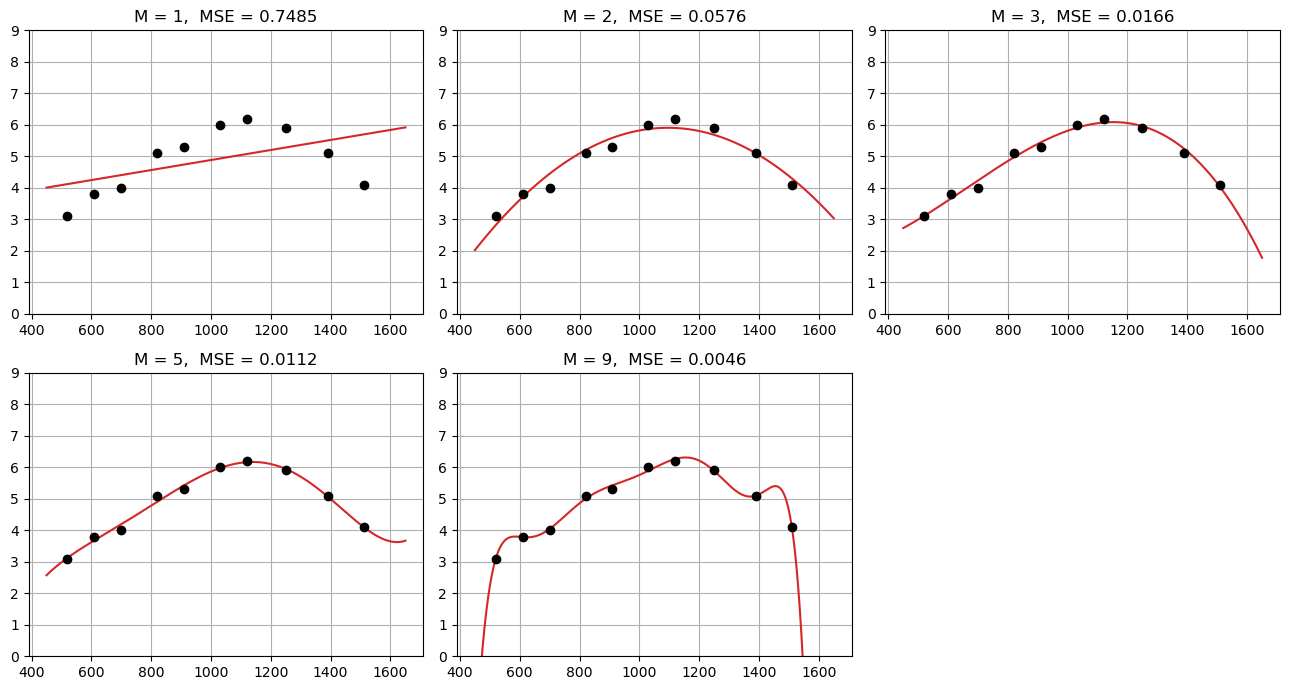

In [5]:
x_grafik = np.linspace(450, 1650, 500)

fig, axs = plt.subplots(2, 3, figsize=(13, 7))
axs = axs.flatten()

for i, M in enumerate(stepeni):
    axs[i].scatter(X, y, color="black", zorder=5)
    axs[i].plot(x_grafik, modeli[M].predict(x_grafik), color="tab:red")
    axs[i].set_title("M = %d,  MSE = %.4f" % (M, modeli[M].score(X, y)))
    axs[i].set_ylim(0, 9)
    axs[i].grid(True)

axs[5].axis("off")
plt.tight_layout()
plt.show()

Za $M = 9$ ($N = M + 1 = 10$) polinom bi teorijski morao da prođe kroz sve tačke (MSE = 0). Pošto $X$ nije normalizovan, matrica $\Phi^\top\Phi$ je jako loše uslovljena, pa `solve` ne daje tačno rešenje:

In [6]:
for M in stepeni:
    Phi = np.vander(X.astype(float), M + 1, increasing=True)
    print("M = %d   cond(Phi^T Phi) = %.1e" % (M, np.linalg.cond(Phi.T @ Phi)))

M = 1   cond(Phi^T Phi) = 1.1e+07
M = 2   cond(Phi^T Phi) = 1.8e+14
M = 3   cond(Phi^T Phi) = 4.2e+21
M = 5   cond(Phi^T Phi) = 5.8e+31
M = 9   cond(Phi^T Phi) = 1.4e+52


### 3.2 Predikcija u novim tačkama

In [7]:
X_novo = np.array([600, 900, 1300, 1600])

predikcije = pd.DataFrame({"X (mm)": X_novo})
for M in stepeni:
    predikcije["M = " + str(M)] = modeli[M].predict(X_novo)

predikcije.round(3)

,X (mm),M = 1,M = 2,M = 3,M = 5,M = 9
0,600,4.245,3.616,3.597,3.622,3.792
1,900,4.723,5.550,5.395,5.373,5.394
2,1300,5.360,5.515,5.776,5.702,5.434
3,1600,5.838,3.528,2.689,3.648,-18.536


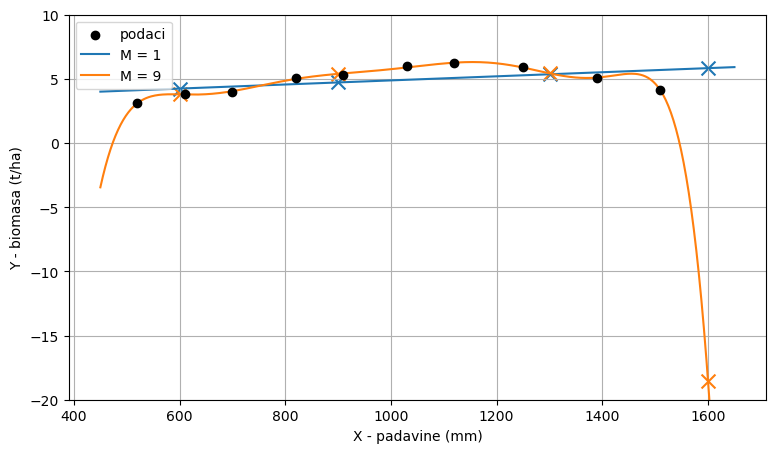

In [8]:
plt.figure(figsize=(9, 5))
plt.scatter(X, y, color="black", zorder=5, label="podaci")

for M in [1, 9]:
    y_kriva = modeli[M].predict(x_grafik)
    linija = plt.plot(x_grafik, y_kriva, label="M = " + str(M))
    boja = linija[0].get_color()
    y_novo = modeli[M].predict(X_novo)
    plt.scatter(X_novo, y_novo, marker="x", s=100, color=boja)

plt.xlabel("X - padavine (mm)")
plt.ylabel("Y - biomasa (t/ha)")
plt.ylim(-20, 10)
plt.legend()
plt.grid(True)
plt.show()

- **$M = 1$**: predikcije stalno rastu (4.25 → 5.84 t/ha), model ne vidi da biomasa posle ~1100 mm opada.
- **$M = 9$**: unutar opsega podataka daje slične vrednosti kao $M = 2, 3$, ali za 1600 mm (van opsega) daje **–18.5 t/ha**, što je nemoguće.

### 3.3 Diskusija

- **Oblik polinoma:** $M = 1$ je prava i ne može da opiše oblik "raste pa opada" – **underfitting**. $M = 2$ i $M = 3$ su glatke krive koje dobro prate trend. Za $M = 5$ i $M = 9$ kriva se uvija da bi prošla kroz svaku tačku, naročito na krajevima – **overfitting**.
- **Greška na obuci** stalno opada sa $M$ (0.748 → 0.005), jer model većeg stepena uvek može bar jednako dobro da se prilagodi. Zato mala greška na obuci ne znači dobar model.
- **Predikcije na novim tačkama:** mali $M$ sistematski greši, a veliki $M$ daje nerealne vrednosti van opsega podataka.

Za ove podatke najbolji su $M = 2$ ili $M = 3$.